In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_TRAIN = 4000
N_TEST = 800
EPOKI = 30
BATCH = 128
LR = 5e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Urządzenie:", DEVICE)
print("Ziarno:", SEED)
print("Zbiór treningowy:", N_TRAIN, "Zbiór testowy:", N_TEST)
print("Epoki:", EPOKI, "Batch:", BATCH, "LR:", LR)

Urządzenie: cpu
Ziarno: 0
Zbiór treningowy: 4000 Zbiór testowy: 800
Epoki: 30 Batch: 128 LR: 0.005


In [ ]:
def generuj_dane(n, dlugosc, seed):
    rng = np.random.default_rng(seed)
    wartosci = rng.random((n, dlugosc), dtype=np.float32)
    znaczniki = np.zeros((n, dlugosc), dtype=np.float32)
    cele = np.empty((n, 1), dtype=np.float32)
    for i in range(n):
        pozycje = rng.choice(np.arange(8, dlugosc), size=2, replace=False)
        znaczniki[i, pozycje] = 1.0
        cele[i, 0] = wartosci[i, pozycje - 8].sum()
    wejscia = np.stack((wartosci, znaczniki), axis=-1)
    return torch.from_numpy(wejscia), torch.from_numpy(cele)

dane = {}
for L in (50, 100):
    dane[L] = (
        *generuj_dane(N_TRAIN, L, 1000 + L),
        *generuj_dane(N_TEST, L, 2000 + L)
    )
    Xtr, Ytr, Xte, Yte = dane[L]
    print(f"L={L}: trening {tuple(Xtr.shape)}, test {tuple(Xte.shape)}")

X, Y = generuj_dane(1, 20, 123)
p = np.flatnonzero(X[0, :, 1].numpy()) + 1
w = p - 8
v = X[0, w - 1, 0].numpy()
print("Znaczniki, kroki:", p.tolist())
print("Wskazywane wartości, kroki:", w.tolist())
print("Wskazywane wartości:", v.tolist())
print("Suma ręczna:", float(v.sum()), "Suma z generatora:", float(Y[0, 0]))
assert np.isclose(v.sum(), float(Y[0, 0]))

L=50: trening (4000, 50, 2), test (800, 50, 2)
L=100: trening (4000, 100, 2), test (800, 100, 2)
Znaczniki, kroki: [9, 15]
Wskazywane wartości, kroki: [1, 7]
Wskazywane wartości: [0.015440523624420166, 0.25508952140808105]
Suma ręczna: 0.2705300450325012 Suma z generatora: 0.2705300450325012


In [ ]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        self.rnn = {"SimpleRNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class ConvNet(nn.Module):
    def __init__(self, channels=64, dylatacje=(1, 2, 4)):
        super().__init__()
        warstwy = []
        wejscie = 2
        for d in dylatacje:
            warstwy.extend([nn.Conv1d(wejscie, channels, kernel_size=3, stride=1, padding=d, dilation=d), nn.ReLU()])
            wejscie = channels
        self.net = nn.Sequential(*warstwy)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def licz_parametry(model):
    return sum(p.numel() for p in model.parameters())

def przygotuj_model(nazwa):
    if nazwa in ("SimpleRNN", "LSTM", "GRU"):
        return RNNNet(nazwa, hidden=64)
    if nazwa == "SimpleRNN_32":
        return RNNNet("SimpleRNN", hidden=32)
    if nazwa == "Conv1D_bez_dylatacji":
        return ConvNet(channels=64, dylatacje=(1, 1, 1))
    return ConvNet(channels=64, dylatacje=(1, 2, 4))

In [ ]:
def synchronizuj():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=EPOKI, lr=LR, batch=BATCH):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xtr = Xtr.to(DEVICE)
    Ytr = Ytr.to(DEVICE)
    Xte = Xte.to(DEVICE)
    Yte = Yte.to(DEVICE)
    n = len(Xtr)
    historia = []
    synchronizuj()
    start = time.perf_counter()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        suma = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            prognoza = model(Xtr[idx])
            strata = loss_fn(prognoza, Ytr[idx])
            strata.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            suma += strata.item() * len(idx)
        historia.append(suma / n)
    synchronizuj()
    czas = time.perf_counter() - start
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(chunk).cpu() for chunk in Xte.split(batch)])
        mse = ((pred - Yte.cpu()) ** 2).mean().item()
    return mse, czas, historia, pred.squeeze(1).numpy()

wyniki = []
historie = {}
predykcje = {}
baseline = {}
nazwy = ("SimpleRNN", "LSTM", "GRU", "Conv1D")

for L in (50, 100):
    Xtr, Ytr, Xte, Yte = dane[L]
    stala = Ytr.mean().item()
    baseline[L] = ((Yte - stala) ** 2).mean().item()
    print(f"L={L}, predykcja stała={stala:.5f}, test MSE={baseline[L]:.6f}")
    for nazwa in nazwy:
        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)
        model = przygotuj_model(nazwa)
        mse, czas, hist, pred = trenuj(model, Xtr, Ytr, Xte, Yte)
        wyniki.append({"L": L, "Model": nazwa, "Test MSE": mse, "Czas [s]": czas, "Parametry": licz_parametry(model)})
        historie[(L, nazwa)] = hist
        predykcje[(L, nazwa)] = pred
        print(f"{nazwa:12} MSE={mse:.6f}, czas={czas:.2f}s, parametry={licz_parametry(model)}")

L=50, predykcja stała=0.98872, test MSE=0.158325
SimpleRNN    MSE=0.159197, czas=13.66s, parametry=4417
LSTM         MSE=0.158347, czas=34.79s, parametry=17473
GRU          MSE=0.079984, czas=36.19s, parametry=13121
Conv1D       MSE=0.157681, czas=33.51s, parametry=25217
L=100, predykcja stała=1.00769, test MSE=0.169684
SimpleRNN    MSE=0.169539, czas=43.83s, parametry=4417
LSTM         MSE=0.170097, czas=80.66s, parametry=17473
GRU          MSE=0.086339, czas=73.51s, parametry=13121
Conv1D       MSE=0.166693, czas=58.90s, parametry=25217


In [ ]:
L = 100
Xtr, Ytr, Xte, Yte = dane[L]

for nazwa in ("SimpleRNN_32", "Conv1D_bez_dylatacji"):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = przygotuj_model(nazwa)
    mse, czas, hist, pred = trenuj(model, Xtr, Ytr, Xte, Yte)
    wyniki.append({"L": L, "Model": nazwa, "Test MSE": mse, "Czas [s]": czas, "Parametry": licz_parametry(model)})
    historie[(L, nazwa)] = hist
    predykcje[(L, nazwa)] = pred
    print(f"{nazwa:24} MSE={mse:.6f}, czas={czas:.2f}s, parametry={licz_parametry(model)}")

rf_dylatowany = 1 + 2 * sum((1, 2, 4))
rf_zwykly = 1 + 2 * sum((1, 1, 1))
print("Pole recepcyjne Conv1D z dylatacjami:", rf_dylatowany)
print("Pole recepcyjne Conv1D bez dylatacji:", rf_zwykly)
print("Odległość pomiędzy znacznikiem a próbką:", 8)
print("Dylatowany może objąć obie pozycje:", rf_dylatowany >= 9)
print("Bez dylatacji może objąć obie pozycje:", rf_zwykly >= 9)

SimpleRNN_32             MSE=0.171255, czas=19.67s, parametry=1185
Conv1D_bez_dylatacji     MSE=0.166729, czas=55.46s, parametry=25217
Pole recepcyjne Conv1D z dylatacjami: 15
Pole recepcyjne Conv1D bez dylatacji: 7
Odległość pomiędzy znacznikiem a próbką: 8
Dylatowany może objąć obie pozycje: True
Bez dylatacji może objąć obie pozycje: False


In [ ]:
tabela = pd.DataFrame(wyniki)
tabela = tabela.sort_values(["L", "Model"]).reset_index(drop=True)
print("Porównanie wszystkich konfiguracji:")
display(tabela.style.format({"Test MSE": "{:.6f}", "Czas [s]": "{:.2f}"}))
print("Predykcja stała:")
display(pd.DataFrame([{"L": L, "Model": "Stała średnia treningowa", "Test MSE": baseline[L]} for L in (50, 100)]).style.format({"Test MSE": "{:.6f}"}))
print("Porównanie SimpleRNN dla L=100:")
display(tabela[(tabela["L"] == 100) & tabela["Model"].isin(["SimpleRNN", "SimpleRNN_32"])])
print("Porównanie Conv1D dla L=100:")
display(tabela[(tabela["L"] == 100) & tabela["Model"].isin(["Conv1D", "Conv1D_bez_dylatacji"])])

Porównanie wszystkich konfiguracji:


,L,Model,Test MSE,Czas [s],Parametry
0,50,Conv1D,0.157681,33.51,25217
1,50,GRU,0.079984,36.19,13121
2,50,LSTM,0.158347,34.79,17473
3,50,SimpleRNN,0.159197,13.66,4417
4,100,Conv1D,0.166693,58.90,25217
5,100,Conv1D_bez_dylatacji,0.166729,55.46,25217
6,100,GRU,0.086339,73.51,13121
7,100,LSTM,0.170097,80.66,17473
8,100,SimpleRNN,0.169539,43.83,4417
9,100,SimpleRNN_32,0.171255,19.67,1185


Predykcja stała:


,L,Model,Test MSE
0,50,Stała średnia treningowa,0.158325
1,100,Stała średnia treningowa,0.169684


Porównanie SimpleRNN dla L=100:


,L,Model,Test MSE,Czas [s],Parametry
8,100,SimpleRNN,0.169539,43.825118,4417
9,100,SimpleRNN_32,0.171255,19.669152,1185


Porównanie Conv1D dla L=100:


,L,Model,Test MSE,Czas [s],Parametry
4,100,Conv1D,0.166693,58.898042,25217
5,100,Conv1D_bez_dylatacji,0.166729,55.457627,25217


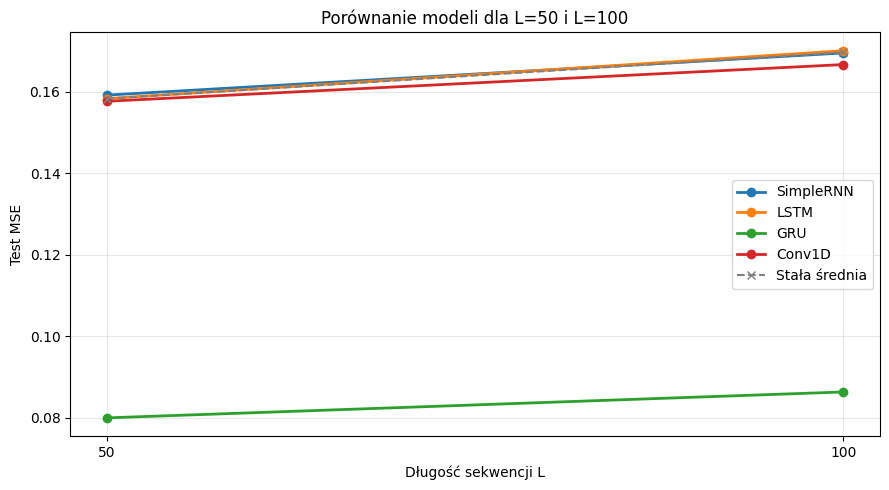

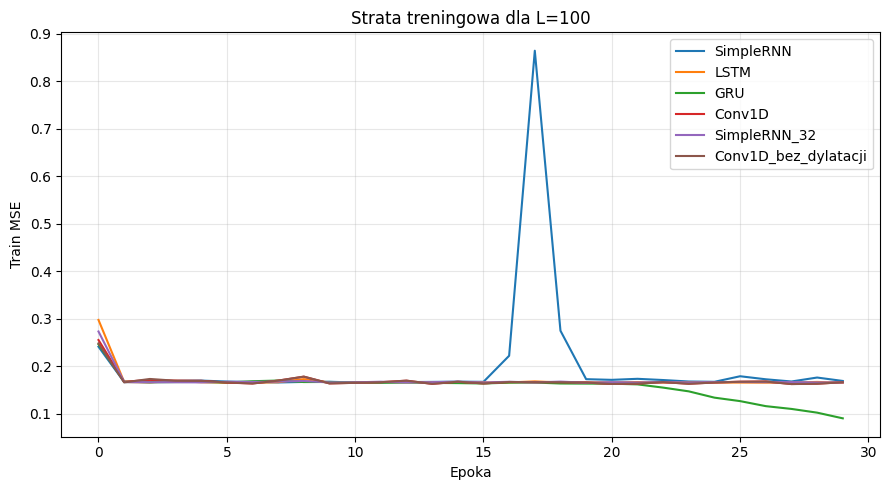

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
for nazwa in nazwy:
    w = tabela[tabela["Model"] == nazwa].sort_values("L")
    ax.plot(w["L"], w["Test MSE"], marker="o", linewidth=2, label=nazwa)
ax.plot([50, 100], [baseline[50], baseline[100]], linestyle="--", color="gray", marker="x", label="Stała średnia")
ax.set_xlabel("Długość sekwencji L")
ax.set_ylabel("Test MSE")
ax.set_title("Porównanie modeli dla L=50 i L=100")
ax.set_xticks([50, 100])
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for nazwa in ("SimpleRNN", "LSTM", "GRU", "Conv1D", "SimpleRNN_32", "Conv1D_bez_dylatacji"):
    ax.plot(historie[(100, nazwa)], label=nazwa)
ax.set_xlabel("Epoka")
ax.set_ylabel("Train MSE")
ax.set_title("Strata treningowa dla L=100")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Model: Conv1D L: 100 Przykład testowy: 610
Znaczniki, kroki: [40, 76]
Wskazywane próbki, kroki: [32, 68]
Wskazywane wartości: [0.005230724811553955, 0.012500166893005371]
Poprawna suma: 0.017730891704559326
Predykcja: 1.0383317470550537
Błąd bezwzględny: 1.0206007957458496
Błąd kwadratowy: 1.0416259765625


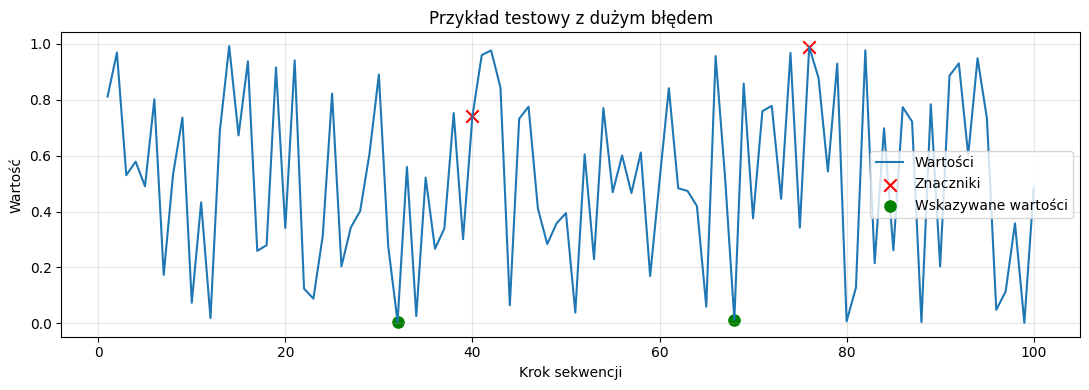

In [ ]:
L = 100
nazwa = "Conv1D"
Xtr, Ytr, Xte, Yte = dane[L]
przewidywania = predykcje[(L, nazwa)]
blad = np.abs(przewidywania - Yte[:, 0].numpy())
i = int(np.argmax(blad))
pozycje = np.flatnonzero(Xte[i, :, 1].numpy()) + 1
wskazane = pozycje - 8
wartosci = Xte[i, wskazane - 1, 0].numpy()
print("Model:", nazwa, "L:", L, "Przykład testowy:", i)
print("Znaczniki, kroki:", pozycje.tolist())
print("Wskazywane próbki, kroki:", wskazane.tolist())
print("Wskazywane wartości:", wartosci.tolist())
print("Poprawna suma:", float(Yte[i, 0]))
print("Predykcja:", float(przewidywania[i]))
print("Błąd bezwzględny:", float(blad[i]))
print("Błąd kwadratowy:", float(blad[i] ** 2))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(np.arange(1, L + 1), Xte[i, :, 0].numpy(), label="Wartości")
ax.scatter(pozycje, Xte[i, pozycje - 1, 0].numpy(), color="red", marker="x", s=80, label="Znaczniki")
ax.scatter(wskazane, wartosci, color="green", s=65, label="Wskazywane wartości")
ax.set_xlabel("Krok sekwencji")
ax.set_ylabel("Wartość")
ax.set_title("Przykład testowy z dużym błędem")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()